# Programming with R Practical 06
## Statistical Analysis of Physical Characteristics of Palmer Penguins
Tanishq Kulkarni  
Rollno: 24102A2007

In [ ]:
p <- read.csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
p$species <- factor(p$species)
p$sex <- factor(p$sex)
b <- subset(p, !is.na(body_mass_g))
s <- subset(b, !is.na(sex))
options(repr.plot.width = 10, repr.plot.height = 5, digits = 5)
cols <- c("#5186A6", "#E6AA50", "#65A28D")
data.frame(Rows = nrow(p), Body_mass = nrow(b), Body_mass_and_sex = nrow(s))
colSums(is.na(p))

  Rows Body_mass Body_mass_and_sex
1  344       342               333
          species            island    bill_length_mm     bill_depth_mm 
                0                 0                 2                 2 
flipper_length_mm       body_mass_g               sex              year 
                2                 2                11                 0 


In [ ]:
describe <- function(x) {
  x <- na.omit(x)
  z <- x - mean(x)
  c(N = length(x), Mean = mean(x), Median = median(x), Min = min(x),
    Max = max(x), Variance = var(x), SD = sd(x), Q1 = unname(quantile(x, .25)),
    Q3 = unname(quantile(x, .75)), IQR = IQR(x),
    Skewness = mean(z^3) / mean(z^2)^1.5,
    Pearson_kurtosis = mean(z^4) / mean(z^2)^2)
}
round(rbind(Overall = describe(b$body_mass_g),
            t(sapply(split(b$body_mass_g, b$species), describe))), 3)

            N   Mean Median  Min  Max Variance     SD     Q1   Q3    IQR
Overall   342 4201.8   4050 2700 6300   643131 801.96 3550.0 4750 1200.0
Adelie    151 3700.7   3700 2850 4775   210283 458.57 3350.0 4000  650.0
Chinstrap  68 3733.1   3700 2700 4800   147713 384.33 3487.5 3950  462.5
Gentoo    123 5076.0   5000 3950 6300   254133 504.12 4700.0 5500  800.0
          Skewness Pearson_kurtosis
Overall      0.468            2.274
Adelie       0.282            2.406
Chinstrap    0.242            3.464
Gentoo       0.069            2.258


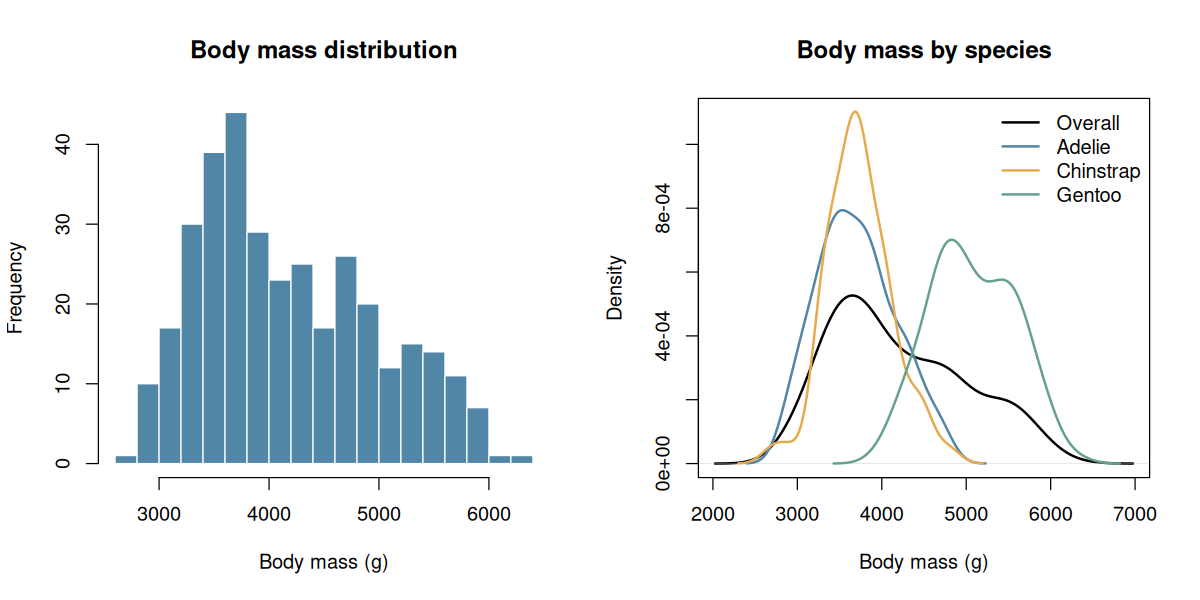

In [ ]:
par(mfrow = c(1, 2))
hist(b$body_mass_g, breaks = 15, col = cols[1], border = "white",
     main = "Body mass distribution", xlab = "Body mass (g)")
plot(density(b$body_mass_g), lwd = 2, main = "Body mass by species",
     xlab = "Body mass (g)", ylim = c(0, .0011))
for (i in 1:3) lines(density(b$body_mass_g[b$species == levels(b$species)[i]]),
                    col = cols[i], lwd = 2)
legend("topright", c("Overall", levels(b$species)), col = c("black", cols), lwd = 2, bty = "n")

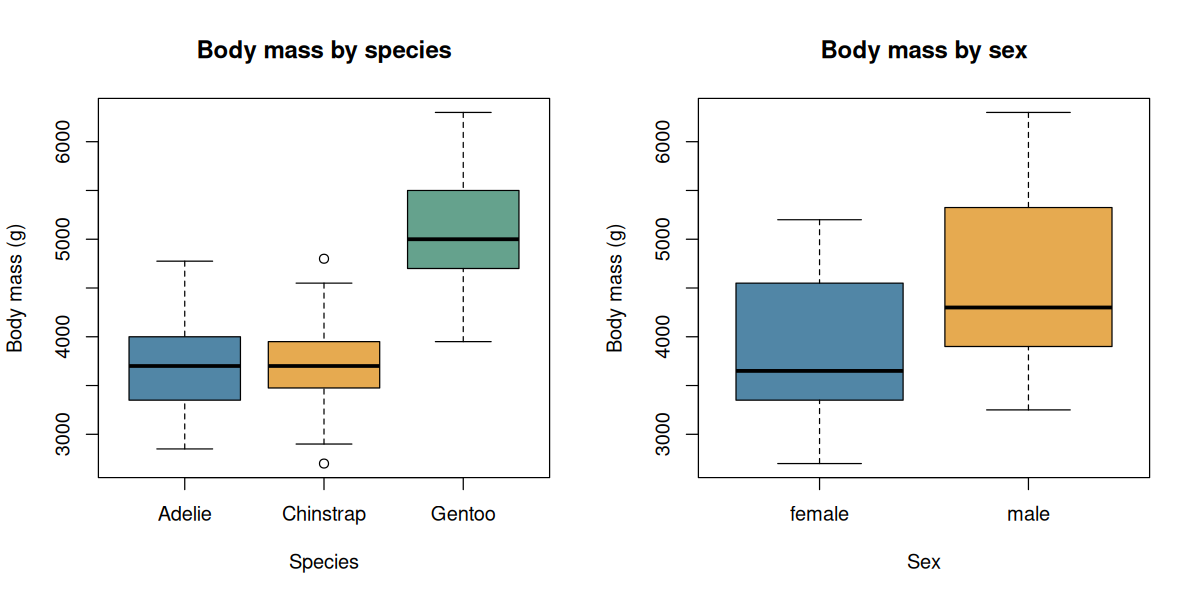

In [ ]:
par(mfrow = c(1, 2))
boxplot(body_mass_g ~ species, b, col = cols, main = "Body mass by species",
        xlab = "Species", ylab = "Body mass (g)")
boxplot(body_mass_g ~ sex, s, col = cols[1:2], main = "Body mass by sex",
        xlab = "Sex", ylab = "Body mass (g)")

             W          p
female 0.91931 6.1553e-08
male   0.92504 1.2268e-07


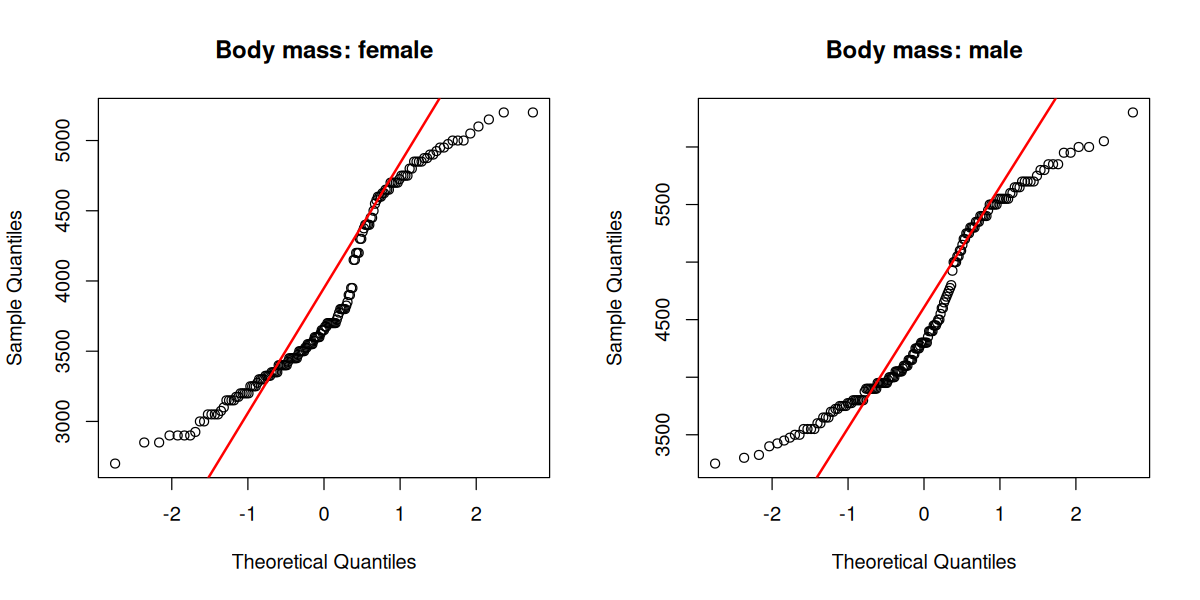

In [ ]:
normality <- function(x) {
  a <- shapiro.test(x)
  c(W = unname(a$statistic), p = a$p.value)
}
t(sapply(split(s$body_mass_g, s$sex), normality))
par(mfrow = c(1, 2))
for (g in levels(s$sex)) {
  x <- s$body_mass_g[s$sex == g]
  qqnorm(x, main = paste("Body mass:", g)); qqline(x, col = "red", lwd = 2)
}

In [ ]:
cat("H0: mean male mass = mean female mass\nH1: mean male mass != mean female mass\n")
male <- s$body_mass_g[s$sex == "male"]
female <- s$body_mass_g[s$sex == "female"]
tt <- t.test(male, female)
tt
pooled_sd <- sqrt(((length(male)-1)*var(male) + (length(female)-1)*var(female)) /
                  (length(male)+length(female)-2))
d <- (mean(male)-mean(female))/pooled_sd
data.frame(Contrast = "Male - Female", Difference_g = mean(male)-mean(female),
           CI_low = tt$conf.int[1], CI_high = tt$conf.int[2], Cohen_d = d,
           Effect = ifelse(abs(d) >= .8, "Large", ifelse(abs(d) >= .5, "Medium", "Small")),
           Reject_H0 = tt$p.value < .05)
cat("Welch test: males are heavier; the 95% CI excludes zero.\n",
    "Pooled groups are non-normal; large samples support the comparison. Species may confound it.\n", sep = "")

H0: mean male mass = mean female mass
H1: mean male mass != mean female mass

	Welch Two Sample t-test

data:  male and female
t = 8.55, df = 324, p-value = 4.8e-16
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 526.25 840.58
sample estimates:
mean of x mean of y 
   4545.7    3862.3 

       Contrast Difference_g CI_low CI_high Cohen_d Effect Reject_H0
1 Male - Female       683.41 526.25  840.58  0.9362  Large      TRUE
Welch test: males are heavier; the 95% CI excludes zero.
Pooled groups are non-normal; large samples support the comparison. Species may confound it.


                W        p
Adelie    0.98071 0.032397
Chinstrap 0.98449 0.560508
Gentoo    0.98593 0.233616


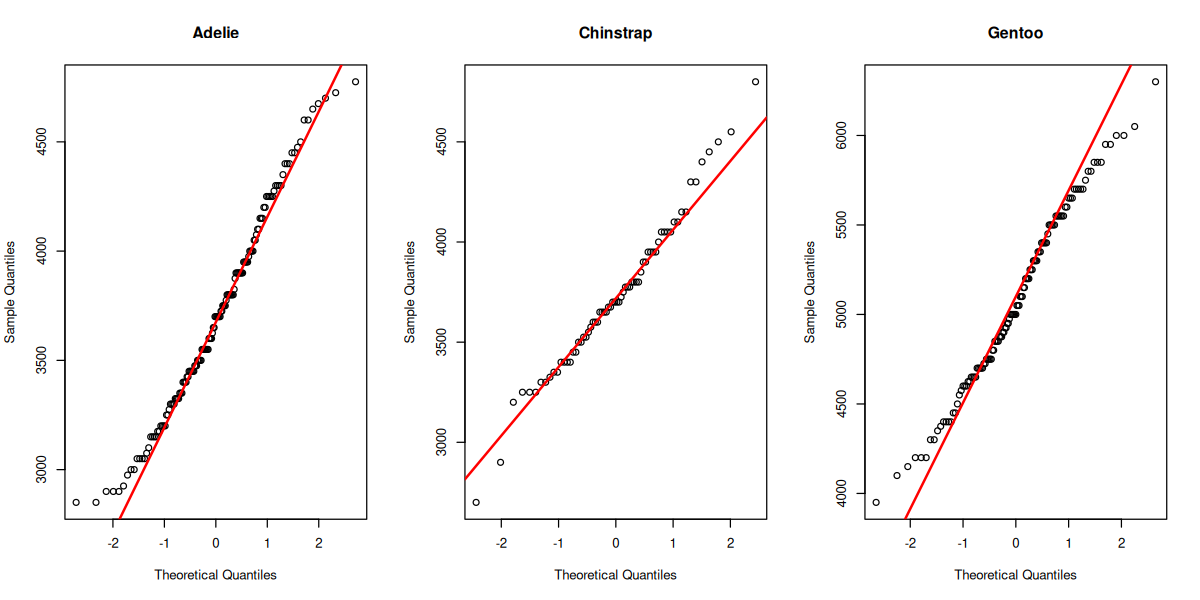

In [ ]:
t(sapply(split(b$body_mass_g, b$species), normality))
par(mfrow = c(1, 3))
for (g in levels(b$species)) {
  x <- b$body_mass_g[b$species == g]
  qqnorm(x, main = g); qqline(x, col = "red", lwd = 2)
}

In [ ]:
levene <- function(y, group) {
  deviation <- abs(y - ave(y, group, FUN = median))
  anova(lm(deviation ~ group))
}
levene(b$body_mass_g, b$species)
one <- aov(body_mass_g ~ species, b)
summary(one)
oneway.test(body_mass_g ~ species, b)
cat("Species means differ. Unequal variances make Welch ANOVA a useful check.\n")

Analysis of Variance Table

Response: deviation
           Df   Sum Sq Mean Sq F value Pr(>F)   
group       2   735914  367957    5.12 0.0064 **
Residuals 339 24361579   71863                  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
             Df   Sum Sq  Mean Sq F value Pr(>F)    
species       2 1.47e+08 73432107     344 <2e-16 ***
Residuals   339 7.24e+07   213698                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

	One-way analysis of means (not assuming equal variances)

data:  body_mass_g and species
F = 318, num df = 2, denom df = 189, p-value <2e-16

Species means differ. Unequal variances make Welch ANOVA a useful check.


  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = body_mass_g ~ species, data = b)

$species
                     diff    lwr     upr   p adj
Chinstrap-Adelie   32.426 -126.5  191.35 0.88067
Gentoo-Adelie    1375.354 1243.2 1507.53 0.00000
Gentoo-Chinstrap 1342.928 1178.5 1507.38 0.00000

              Pair Reject_H0
1 Chinstrap-Adelie     FALSE
2    Gentoo-Adelie      TRUE
3 Gentoo-Chinstrap      TRUE
Gentoo differs from both other species; Adelie and Chinstrap do not differ significantly.
Intervals crossing zero indicate no significant difference. Tukey assumes equal variances.


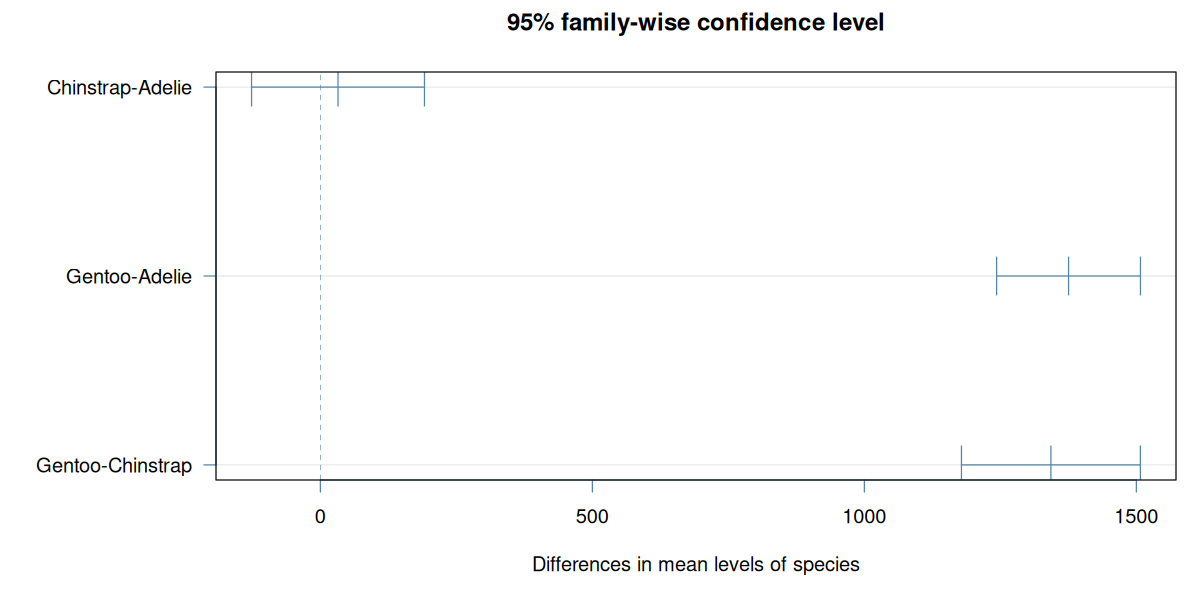

In [ ]:
post <- TukeyHSD(one)
post
data.frame(Pair = rownames(post$species), Reject_H0 = post$species[, "p adj"] < .05,
           row.names = NULL)
par(mfrow = c(1, 1), mar = c(5, 9, 3, 1))
plot(post, las = 1, col = cols[1])
cat("Gentoo differs from both other species; Adelie and Chinstrap do not differ significantly.\n",
    "Intervals crossing zero indicate no significant difference. Tukey assumes equal variances.\n", sep = "")

In [ ]:
kw <- kruskal.test(body_mass_g ~ species, b)
kw
data.frame(Test = c("ANOVA", "Welch ANOVA", "Kruskal-Wallis"),
           p = c(summary(one)[[1]][1, "Pr(>F)"],
                 oneway.test(body_mass_g ~ species, b)$p.value, kw$p.value))
cat("All three tests detect species differences. Kruskal-Wallis compares ranks, not means.\n")


	Kruskal-Wallis rank sum test

data:  body_mass_g by species
Kruskal-Wallis chi-squared = 218, df = 2, p-value <2e-16

            Test          p
1          ANOVA 2.8924e-82
2    Welch ANOVA 3.0937e-61
3 Kruskal-Wallis 5.6095e-48
All three tests detect species differences. Kruskal-Wallis compares ranks, not means.


Single term deletions

Model:
body_mass_g ~ species * sex
            Df Sum of Sq      RSS  AIC F value Pr(>F)    
<none>                   3.13e+07 3825                   
species      2  1.43e+08 1.74e+08 4393  746.92 <2e-16 ***
sex          1  2.99e+07 6.12e+07 4046  311.84 <2e-16 ***
species:sex  2  1.68e+06 3.30e+07 3839    8.76  2e-04 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

	Shapiro-Wilk normality test

data:  residuals(two)
W = 0.998, p-value = 0.94

Analysis of Variance Table

Response: deviation
           Df   Sum Sq Mean Sq F value Pr(>F)
group       5   240535   48107    1.39   0.23
Residuals 327 11310528   34589               
    species    sex body_mass_g
1    Adelie female      3368.8
2 Chinstrap female      3527.2
3    Gentoo female      4679.7
4    Adelie   male      4043.5
5 Chinstrap   male      3939.0
6    Gentoo   male      5484.8
Species, sex and their interaction are significant. The male-female mass gap varies by species.


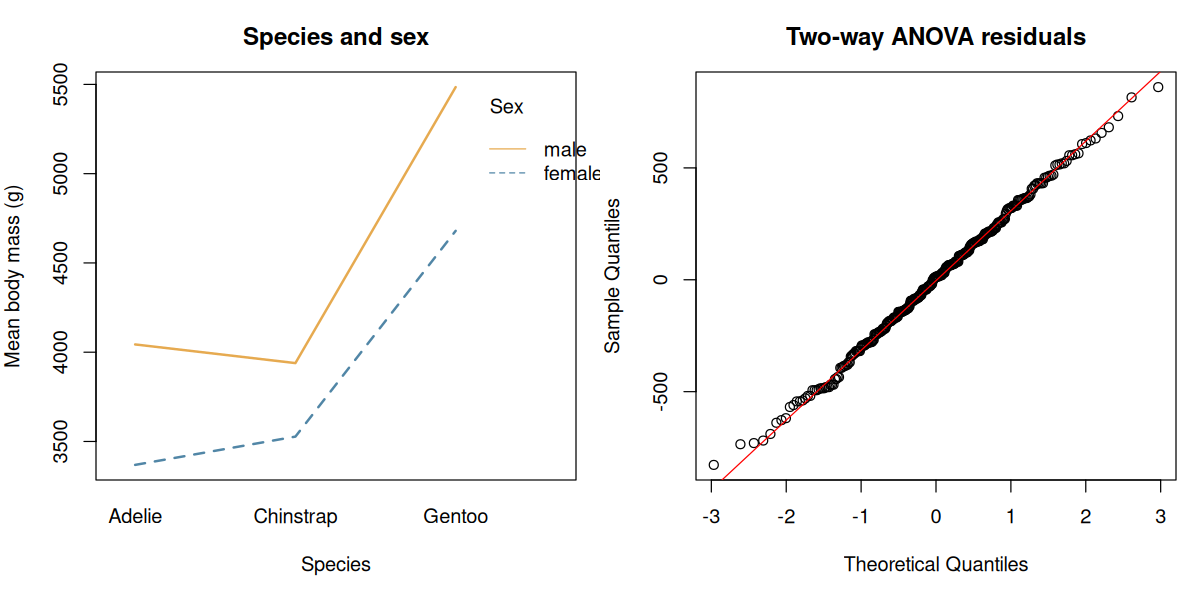

In [ ]:
options(contrasts = c("contr.sum", "contr.poly"))
two <- lm(body_mass_g ~ species * sex, s)
drop1(two, scope = ~ species * sex, test = "F")
shapiro.test(residuals(two))
levene(s$body_mass_g, interaction(s$species, s$sex))
aggregate(body_mass_g ~ species + sex, s, mean)
par(mfrow = c(1, 2), mar = c(5, 4, 3, 1))
with(s, interaction.plot(species, sex, body_mass_g, col = cols[1:2], lwd = 2,
                         xlab = "Species", ylab = "Mean body mass (g)",
                         main = "Species and sex", trace.label = "Sex"))
qqnorm(residuals(two), main = "Two-way ANOVA residuals")
qqline(residuals(two), col = "red")
cat("Species, sex and their interaction are significant. The male-female mass gap varies by species.\n")

In [ ]:
f <- subset(p, !is.na(flipper_length_mm))
round(t(sapply(split(f$flipper_length_mm, f$species), describe)), 3)
t(sapply(split(f$flipper_length_mm, f$species), normality))
levene(f$flipper_length_mm, f$species)
flipper <- aov(flipper_length_mm ~ species, f)
summary(flipper)
TukeyHSD(flipper)
kruskal.test(flipper_length_mm ~ species, f)
cat("Flipper length differs across all three species. Gentoo has the longest flippers.\n",
    "Unlike body mass, the Adelie-Chinstrap flipper difference is also significant.\n", sep = "")

            N   Mean Median Min Max Variance    SD  Q1  Q3 IQR Skewness
Adelie    151 189.95    190 172 210   42.765 6.539 186 195   9    0.086
Chinstrap  68 195.82    196 178 212   50.864 7.132 191 201  10   -0.009
Gentoo    123 217.19    216 203 231   42.055 6.485 212 221   9    0.390
          Pearson_kurtosis
Adelie               3.282
Chinstrap            2.956
Gentoo               2.400
                W         p
Adelie    0.99339 0.7200466
Chinstrap 0.98891 0.8106447
Gentoo    0.96219 0.0016198
Analysis of Variance Table

Response: deviation
           Df Sum Sq Mean Sq F value Pr(>F)
group       2     11     5.7    0.33   0.72
Residuals 339   5843    17.2               
             Df Sum Sq Mean Sq F value Pr(>F)    
species       2  52473   26237     595 <2e-16 ***
Residuals   339  14953      44                   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = 

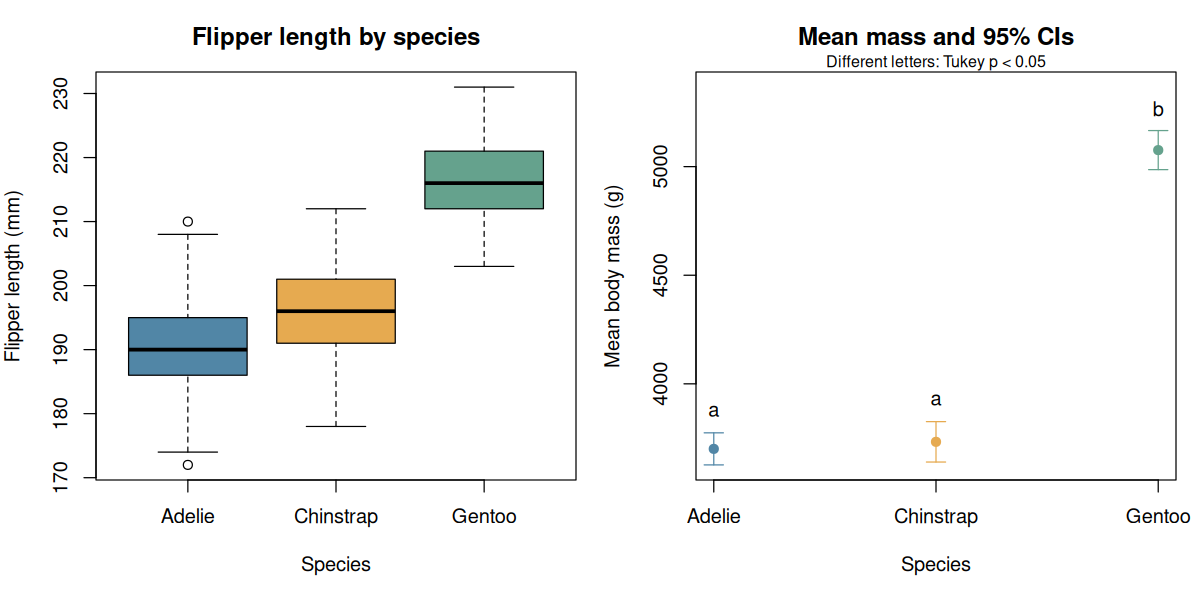

In [ ]:
par(mfrow = c(1, 2), mar = c(5, 4, 3, 1))
boxplot(flipper_length_mm ~ species, f, col = cols, main = "Flipper length by species",
        xlab = "Species", ylab = "Flipper length (mm)")
means <- tapply(b$body_mass_g, b$species, mean)
se <- tapply(b$body_mass_g, b$species, function(x) sd(x)/sqrt(length(x)))
ci <- qt(.975, table(b$species)-1)*se
plot(1:3, means, ylim = range(means-ci, means+ci+200), xaxt = "n", pch = 19,
     col = cols, xlab = "Species", ylab = "Mean body mass (g)",
     main = "Mean mass and 95% CIs")
axis(1, 1:3, names(means))
arrows(1:3, means-ci, 1:3, means+ci, angle = 90, code = 3, length = .08, col = cols)
text(1:3, means+ci+100, c("a", "a", "b"))
mtext("Different letters: Tukey p < 0.05", side = 3, cex = .8)